# Spearman Rank Correlation

## Problem: Product Price vs Customer Rating

We want to investigate whether higher-priced audio products tend to receive higher customer ratings.

### Hypotheses

- **\(H_0\):** There is no monotonic association between sale price and customer rating in the population (\(rho_s=0\)).
- **\(H_1\):** There is a monotonic association between sale price and customer rating in the population (\(rho_s!=0\)).

We use Spearman rank correlation because it evaluates monotonic association using ranks rather than requiring a linear relationship between the original values.

We will use a two-sided test with a significance level of \(alpha=0.05\).

In [1]:
import pandas as pd
from scipy.stats import spearmanr

df = pd.read_csv("../data/boat_vs_noise_audio_products.csv")

print(df.shape)
print(df[["sale_price", "rating"]].dtypes)
print(df[["sale_price", "rating"]].isna().sum())

(518, 28)
sale_price      int64
rating        float64
dtype: object
sale_price    0
rating        0
dtype: int64


In [2]:
data = df[["sale_price", "rating"]].copy()

data["sale_price"] = pd.to_numeric(
    data["sale_price"], errors="coerce"
)

data["rating"] = pd.to_numeric(
    data["rating"], errors="coerce"
)

data = data.dropna()

print("Observations used:", len(data))
print(data.describe())

Observations used: 518
        sale_price      rating
count   518.000000  518.000000
mean   1639.129344    4.737181
std     945.551399    0.260123
min     249.000000    3.000000
25%    1099.000000    4.700000
50%    1399.000000    4.800000
75%    1899.000000    4.900000
max    6499.000000    5.000000


## Assumption Checks

Before running the test, we need to verify that:

1. Both variables are numeric or meaningfully ordinal.
2. Each observation represents an independent unit. Repeated product listings or related records may violate this assumption.
3. The relationship is reasonably monotonic; it should generally move in one direction, though it need not be linear.
4. Missing and invalid values are handled appropriately.

The dataset contains repeated `product_id` values, so we must investigate whether records represent repeated listings or related variants before treating all rows as independent observations.

In [3]:
print("Duplicate rows:", data.duplicated().sum())

print(
    "Unique sale prices:",
    data["sale_price"].nunique()
)

print(
    "Unique ratings:",
    data["rating"].nunique()
)

Duplicate rows: 274
Unique sale prices: 72
Unique ratings: 46


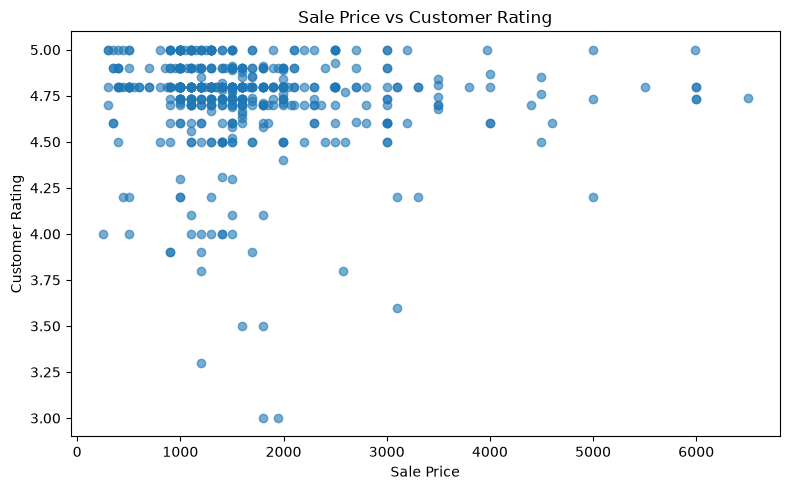

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(data["sale_price"], data["rating"], alpha=0.6)

plt.xlabel("Sale Price")
plt.ylabel("Customer Rating")
plt.title("Sale Price vs Customer Rating")
plt.tight_layout()
plt.show()

In [5]:
rho, p_value = spearmanr(
    data["sale_price"],
    data["rating"]
)

alpha = 0.05

print(f"Spearman correlation: {rho:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < alpha:
    print("Reject H0: Evidence of a monotonic association.")
else:
    print("Fail to reject H0: Insufficient evidence of a monotonic association.")

Spearman correlation: -0.1465
P-value: 0.0008
Reject H0: Evidence of a monotonic association.


## Interpretation of Results

Spearman's correlation coefficient (\(rho_s\)) ranges from \(-1\) to \(+1\).

- A positive value indicates that higher prices tend to accompany higher ratings.
- A negative value indicates that higher prices tend to accompany lower ratings.
- A value near zero indicates little or no monotonic association.

The p-value assesses evidence against the null hypothesis. A statistically significant result does not necessarily imply a strong relationship, and correlation does not establish causation.





The Spearman rank correlation analysis between sale price and customer rating produced the following results:

- **Spearman's correlation coefficient (\(rho_s\)):** -0.1465
- **P-value:** 0.0008
- **Significance level (\(alpha\)):** 0.05

Since the p-value is below 0.05, we reject the null hypothesis of no monotonic association.

The negative coefficient indicates a **weak negative monotonic association** between sale price and customer rating. In this dataset, higher-priced products tend to be associated with slightly lower ratings, although the relationship is weak.

The p-value indicates statistical significance, while Spearman's correlation coefficient indicates the direction and strength of the association. Since the coefficient itself serves as an effect-size measure, a separate effect-size statistic is not necessary here.

### Conclusion

There is statistically significant evidence of a weak negative monotonic association between sale price and customer rating in this dataset. However, this does not establish causation, and the weak correlation does not imply that every higher-priced product receives a lower rating. The findings should be interpreted in the context of the dataset and its sampling limitations.